In [157]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [158]:
import sys
sys.path.append("../src")

In [159]:
DATA_DIR = "../data/troupe/TLS"

In [160]:
import pickle

with open(f"{DATA_DIR}/processed_data/trees.pkl", "rb") as f:
    data = pickle.load(f)

print(type(data))

<class 'list'>


In [161]:
len(data)

12

In [162]:
t_id = 0
t = data[t_id]
t.describe()
# t.convert_to_ultrametric()
t.describe()

# t.show()
# t.write(outfile='test.nwk')

Number of leaf nodes:	214
Total number of nodes:	427
Rooted:	Yes
Most distant node:	ATGCGATGTCTTTATC-1
Max. distance:	0.992467
Number of leaf nodes:	214
Total number of nodes:	427
Rooted:	Yes
Most distant node:	ATGCGATGTCTTTATC-1
Max. distance:	0.992467


In [163]:
import networkx as nx

def ete_to_nx(t):
    G = nx.DiGraph()

    node_ids = {}
    
    for i, node in enumerate(t.traverse("preorder")):
        node_ids[node] = i

    for node in t.traverse("preorder"):
        node_id = node_ids[node]

        attrs = {
            "name": node.name,
            "dist": node.dist,
            "is_leaf": node.is_leaf()
        }

        for attr in ["state", "state_coarse", "state_fine"]:
            if hasattr(node, attr):
                attrs[attr] = getattr(node, attr)

        G.add_node(node_id, **attrs)

        if node.up:
            G.add_edge(node_ids[node.up], node_id, weight=node.dist)

    G.graph["root"] = node_ids[t]

    return G

In [164]:
T = ete_to_nx(t)
T

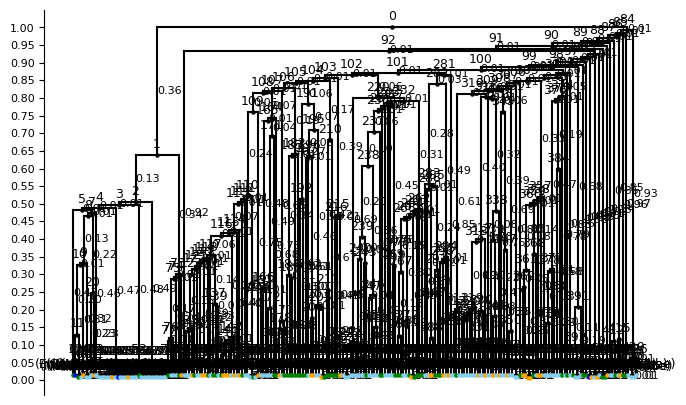

In [165]:
from plotters import draw_ultrametric_tree

draw_ultrametric_tree(T, root=T.graph['root'])

In [166]:
leaves = [n for n, d in T.out_degree() if d == 0]

In [167]:
# If edges have weight attribute 'length' or similar
distances = {}
for leaf in leaves:
    distances[leaf] = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='weight')

In [168]:
min_dist = min(distances.values())
max_dist = max(distances.values())
print(min_dist, max_dist)

0.9849348136938565 0.9924674085576397


In [169]:
EPS = 1e-6
scale = (1 - EPS) / min_dist  # scale to make the min leaf at 1

In [170]:
for u, v, d in T.edges(data=True):
    d['weight'] *= scale

In [171]:
for leaf in leaves:
    dist = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='weight')
    
    if dist > 1.0:
        parent = list(T.predecessors(leaf))[0]
        
        edge_length = T[parent][leaf]['weight']
        
        excess = dist - 1.0
        T[parent][leaf]['weight'] = max(edge_length - excess, 0)  # avoid negative lengths

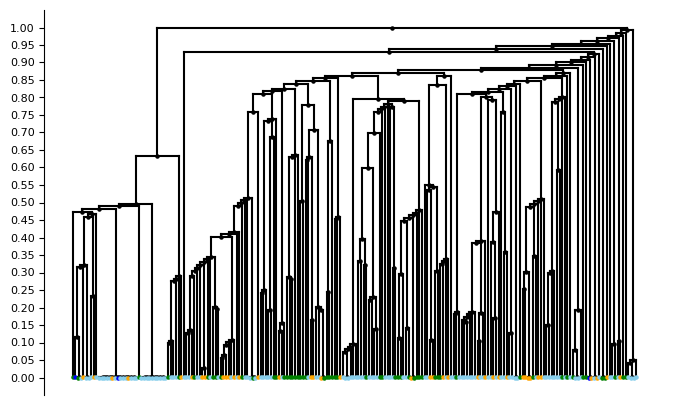

In [172]:
draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False)

In [173]:
# If edges have weight attribute 'length' or similar
distances = {}
for leaf in leaves:
    distances[leaf] = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='weight')

In [174]:
min_dist = min(distances.values())
max_dist = max(distances.values())
print(min_dist, max_dist)

0.999999 1.0


## Differentiation Map from CARTA

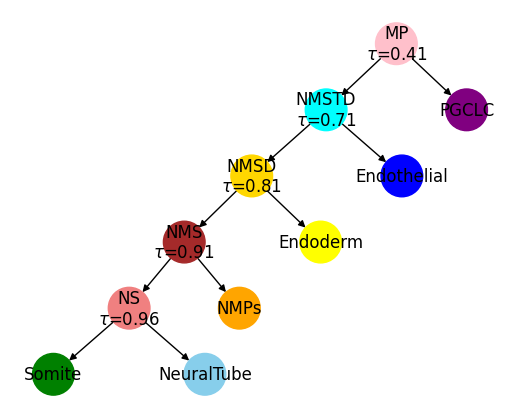

In [175]:
import string
from plotters import plot_differentiation_tree

diff_map_edges = [
    ("MP", "PGCLC"),
    ("MP", "NMSTD"),
    ("NMSTD", "NMSD"),
    ("NMSTD", "Endothelial"),
    ("NMSD", "NMS"),
    ("NMSD", "Endoderm"),
    ("NMS", "NS"),
    ("NMS", "NMPs"),
    ("NS", "Somite"),
    ("NS", "NeuralTube"),
]

a = 0.96
b = 0.05
c = 0.1
d = 0.1
e = 0.3

diff_times = {
    "MP":  a- b - c - d - e,
    "NMSTD": a - b - c - d,
    "NMSD": a - b - c,
    "NMS": a - b,
    "NS": a,
    "PGCLC": None,
    "Endothelial": None,
    "Endoderm": None,
    "NMPs": None,
    "Somite": None,
    "NeuralTube": None
}

diff_T = nx.DiGraph()


for k, v in diff_times.items():
    diff_T.add_node(k, diff_time=v)

for s, e in diff_map_edges:
    diff_T.add_edge(s, e)

plot_differentiation_tree(diff_T)

In [176]:
from likelihood import add_node_times
T = add_node_times(T, root=T.graph['root'])

In [177]:
from likelihood import assign_states_to_internal_nodes

T = assign_states_to_internal_nodes(T, diff_T, correct=True)

Children have > 1 types ['NMPs', 'Somite'] at 9.98592112111396e-07
Setting state for descendant 276 at 0.0 to ?
Setting state for descendant 277 at 0.0 to ?
Children have > 1 types ['NMPs', 'Somite'] at 9.98690086961851e-07
Setting state for descendant 208 at 0.0 to ?
Setting state for descendant 209 at 0.0 to ?
Children have > 1 types ['Somite', 'NeuralTube'] at 9.990274405513588e-07
Setting state for descendant 161 at 0.0 to ?
Setting state for descendant 162 at 0.0 to ?
Children have > 1 types ['NMPs', 'Endothelial'] at 9.991165306200145e-07
Setting state for descendant 401 at 0.0 to ?
Setting state for descendant 402 at 0.0 to ?
Children have > 1 types ['Somite', 'NeuralTube'] at 9.99824434355645e-07
Setting state for descendant 14 at 0.0 to ?
Setting state for descendant 15 at 0.0 to ?
Children have > 1 types ['NMPs', 'NeuralTube'] at 9.998374326247728e-07
Setting state for descendant 404 at 0.0 to ?
Setting state for descendant 405 at 0.0 to ?
Children have > 1 types ['NMPs', 'Ne

In [178]:
T.nodes[34]

{'name': '',
 'dist': 0.0,
 'is_leaf': False,
 'T': 9.998599010963005e-07,
 'state': '?'}

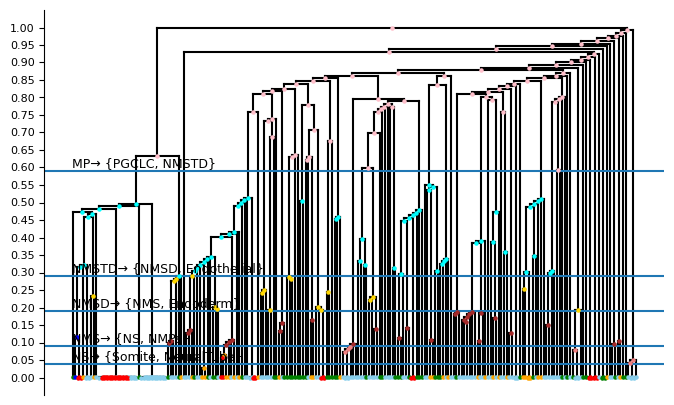

In [179]:
draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False, diff_T=diff_T)

In [180]:
types = list(diff_T.nodes())

transition_maps = [
    (i, succ)
    for i in diff_T.nodes()
    if (succ := list(diff_T.successors(i)))
]

print(types)
print(transition_maps)

['MP', 'NMSTD', 'NMSD', 'NMS', 'NS', 'PGCLC', 'Endothelial', 'Endoderm', 'NMPs', 'Somite', 'NeuralTube']
[('MP', ['PGCLC', 'NMSTD']), ('NMSTD', ['NMSD', 'Endothelial']), ('NMSD', ['NMS', 'Endoderm']), ('NMS', ['NS', 'NMPs']), ('NS', ['Somite', 'NeuralTube'])]


In [181]:
import numpy as np
import pandas as pd
from likelihood import calculate_likelihood_of_tree
from scipy.optimize import minimize


def unpack_params(theta):
    
    k = 0

    death = {}
    for t in types:
        death[t] = np.exp(theta[k])
        k += 1

    # Birth rates (strictly greater than death)
    birth = {}
    for t in types:
        birth[t] = death[t] + np.exp(theta[k])
        k += 1

    # Transition matrix via softmax
    Q = pd.DataFrame(0.0, index=types, columns=types)

    for i, transition_to in transition_maps:
        logits = []
        js = []

        for j in transition_to:
            logits.append(theta[k])
            js.append(j)
            k += 1

        logits = np.array(logits)
        logits -= np.max(logits)  # numerical stability
        exp_logits = np.exp(logits)
        probs = exp_logits / exp_logits.sum()

        for idx, j in enumerate(js):
            Q.loc[i, j] = probs[idx]

    return birth, death, Q

def neg_log_likelihood(theta, cell_lineage_T, diff_T, sampling_rate=1.0):
    birth, death, Q = unpack_params(theta)

    try:

        p, _, _ = calculate_likelihood_of_tree(
            birth_rates=birth,
            death_rates=death,
            sampling_rate=sampling_rate,
            transition_probabilities=Q,
            cell_lineage_T=cell_lineage_T,
            diff_T=diff_T
        )
    except Exception as e:
        return 1e300

    if p <= 1e-300:
        return 1e300

    return -np.log(p)

def pack_initial():
    params = []
    
    # log death
    for t in types:
        params.append(np.log(0.5))

    # log birth
    for t in types:
        params.append(np.log(2))

    # transition logits (inverse softmax approx)
    for i, transition_to in transition_maps:
        for j in transition_to:
            params.append(np.log(0.5))

    return np.array(params)


def find_params(cell_lineage_T, diff_T):
    theta0 = pack_initial()

    result = minimize(
        neg_log_likelihood,
        theta0,
        args=(cell_lineage_T, diff_T, 1.0),
        method="L-BFGS-B"
    )

    return unpack_params(result.x)


In [182]:
birth_rates, death_rates, Q = find_params(T, diff_T)
birth_rates, death_rates, Q

/Users/samin/workspace/phylodynamic-carta/notebooks/../src/likelihood.py:25: RuntimeWarning: invalid value encountered in scalar divide
  else: diff_time = 1 - diff_time
/Users/samin/workspace/phylodynamic-carta/notebooks/../src/likelihood.py:54: RuntimeWarning: invalid value encountered in scalar divide
  
/var/folders/nz/jn74t1g51q10qyclfkkr8cgm0000gq/T/ipykernel_69679/3485079054.py:13: RuntimeWarning: overflow encountered in exp
  death[t] = np.exp(theta[k])
/Users/samin/workspace/phylodynamic-carta/notebooks/../src/likelihood.py:24: RuntimeWarning: invalid value encountered in scalar divide
  if diff_time is None: diff_time = 0
/Users/samin/workspace/phylodynamic-carta/notebooks/../src/likelihood.py:25: RuntimeWarning: invalid value encountered in scalar subtract
  else: diff_time = 1 - diff_time
/var/folders/nz/jn74t1g51q10qyclfkkr8cgm0000gq/T/ipykernel_69679/3485079054.py:19: RuntimeWarning: overflow encountered in exp
  birth[t] = death[t] + np.exp(theta[k])
/Users/samin/workspa

({'MP': np.float64(3.3325840599735),
  'NMSTD': np.float64(5.0808477841774975),
  'NMSD': np.float64(2.845923932377136),
  'NMS': np.float64(0.6240683283938238),
  'NS': np.float64(0.02767378944061415),
  'PGCLC': np.float64(2.4305838966413487),
  'Endothelial': np.float64(64.15208301452179),
  'Endoderm': np.float64(2.6570132599085308),
  'NMPs': np.float64(0.12903208222623458),
  'Somite': np.float64(0.28077539046964034),
  'NeuralTube': np.float64(5758.590426346812)},
 {'MP': np.float64(0.1981344230111196),
  'NMSTD': np.float64(0.18371885281570682),
  'NMSD': np.float64(0.35691797150216614),
  'NMS': np.float64(0.3845821092650504),
  'NS': np.float64(0.026839923502179078),
  'PGCLC': np.float64(0.9489854504055476),
  'Endothelial': np.float64(1.8741525822425738),
  'Endoderm': np.float64(0.8269823236754464),
  'NMPs': np.float64(0.11249343547268037),
  'Somite': np.float64(0.20516691895701858),
  'NeuralTube': np.float64(5707.138092413747)},
               MP     NMSTD      NMSD  N

In [183]:
likelihood, L, U = calculate_likelihood_of_tree(
    birth_rates=birth_rates,
    death_rates=death_rates,
    sampling_rate=1.0,
    transition_probabilities=Q,
    cell_lineage_T=T,
    diff_T=diff_T
)
likelihood

np.float64(1.2965927828416731e+42)

In [184]:
pack_initial()

array([-0.69314718, -0.69314718, -0.69314718, -0.69314718, -0.69314718,
       -0.69314718, -0.69314718, -0.69314718, -0.69314718, -0.69314718,
       -0.69314718,  0.69314718,  0.69314718,  0.69314718,  0.69314718,
        0.69314718,  0.69314718,  0.69314718,  0.69314718,  0.69314718,
        0.69314718,  0.69314718, -0.69314718, -0.69314718, -0.69314718,
       -0.69314718, -0.69314718, -0.69314718, -0.69314718, -0.69314718,
       -0.69314718, -0.69314718])

In [185]:
T.nodes[35]

{'name': '',
 'dist': 0.0,
 'is_leaf': False,
 'T': 9.998599010963005e-07,
 'state': '?'}

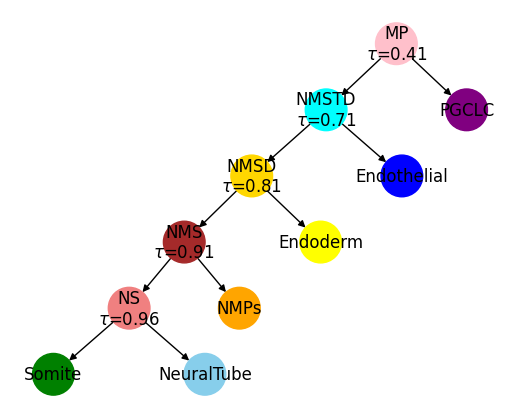

In [186]:
plot_differentiation_tree(diff_T)

In [187]:
from collections import defaultdict

edge_ml = defaultdict(float)

for (u, v, t, s), val in L.items():
    edge_ml[(u, v)] = max(edge_ml[(u, v)], float(val))

zero_ml_edges = {e for e, v in edge_ml.items() if v == 0}


In [188]:
zero_ml_edges

{(0, 84),
 (84, 85),
 (85, 86),
 (86, 87),
 (87, 88),
 (88, 89),
 (89, 90),
 (90, 91),
 (91, 92),
 (92, 94),
 (94, 95),
 (95, 96),
 (96, 97),
 (97, 98),
 (98, 99),
 (99, 100)}

In [189]:
for e1, e2 in T.edges():
    if (e1, e2) in zero_ml_edges: 
    # and T.nodes[e2]['T'] == 0:
        print(e1, e2, T.nodes[e1]['T'], T.nodes[e2]['T'], T.nodes[e2]['state'])

0 84 1 0.9923522006158493 MP
84 85 0.9923522006158493 0.9847044012987551 MP
85 86 0.9847044012987551 0.9770566021202334 MP
86 87 0.9770566021202334 0.9694088029457714 MP
87 88 0.9694088029457714 0.9617610038619221 MP
88 89 0.9617610038619221 0.9541132048212446 MP
89 90 0.9541132048212446 0.946465405762189 MP
90 91 0.946465405762189 0.938817606760372 MP
91 92 0.938817606760372 0.9311698077748766 MP
92 94 0.9311698077748766 0.9235220087534696 MP
94 95 0.9235220087534696 0.9158742097728926 MP
95 96 0.9158742097728926 0.908226410822347 MP
96 97 0.908226410822347 0.9005786118816923 MP
97 98 0.9005786118816923 0.8929308129255634 MP
98 99 0.8929308129255634 0.885283013926753 MP
99 100 0.885283013926753 0.8776352149968383 MP


In [190]:
T.nodes[34]

{'name': '',
 'dist': 0.0,
 'is_leaf': False,
 'T': 9.998599010963005e-07,
 'state': '?'}

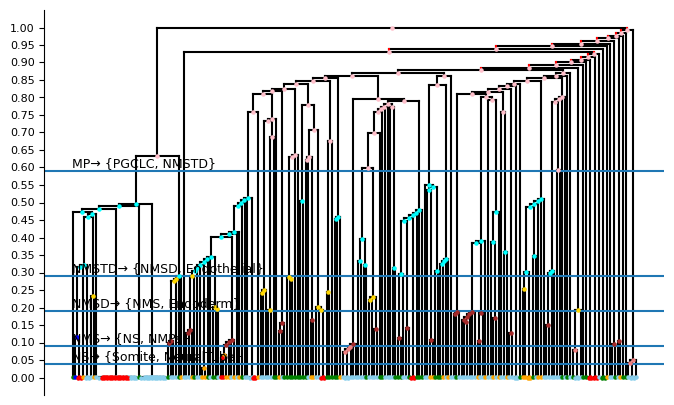

In [191]:
draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False, diff_T=diff_T, red_edges=zero_ml_edges)

In [192]:
# for e1, e2 in T.edges():
#     if T.nodes[e2]['state'] == "?":
#         for k, v in L.items():
#             e_1, e_2, t, s = k
#             if e_1 == e1 and e_2 == e2:
#                 print(k, v)

for e1, e2 in T.edges():
    for k, v in L.items():
        e_1, e_2, t, s = k
        if e1 == e_1 and e2 == e_2 and v == 0 and T.nodes[e2]['T'] == 0:
            print(k, v, T.nodes[e2]['state'], T.nodes[e2]['T'])

(17, 18, 9.99824434355645e-07, 'Somite') 0.0 NeuralTube 0.0
(17, 18, 9.99824434355645e-07, 'NMPs') 0.0 NeuralTube 0.0
(17, 18, 9.99824434355645e-07, 'Endoderm') 0.0 NeuralTube 0.0
(17, 18, 9.99824434355645e-07, 'Endothelial') 0.0 NeuralTube 0.0
(17, 18, 9.99824434355645e-07, 'PGCLC') 0.0 NeuralTube 0.0
(17, 19, 9.99824434355645e-07, 'Somite') 0.0 NeuralTube 0.0
(17, 19, 9.99824434355645e-07, 'NMPs') 0.0 NeuralTube 0.0
(17, 19, 9.99824434355645e-07, 'Endoderm') 0.0 NeuralTube 0.0
(17, 19, 9.99824434355645e-07, 'Endothelial') 0.0 NeuralTube 0.0
(17, 19, 9.99824434355645e-07, 'PGCLC') 0.0 NeuralTube 0.0
(24, 25, 9.998599010963005e-07, 'Somite') 0.0 NeuralTube 0.0
(24, 25, 9.998599010963005e-07, 'NMPs') 0.0 NeuralTube 0.0
(24, 25, 9.998599010963005e-07, 'Endoderm') 0.0 NeuralTube 0.0
(24, 25, 9.998599010963005e-07, 'Endothelial') 0.0 NeuralTube 0.0
(24, 25, 9.998599010963005e-07, 'PGCLC') 0.0 NeuralTube 0.0
(26, 52, 9.998599010963005e-07, 'Somite') 0.0 NeuralTube 0.0
(26, 52, 9.99859901096

### Using given ultrametric transformation function

In [30]:
t.convert_to_ultrametric()
T = ete_to_nx(t)
draw_ultrametric_tree(T, root=T.graph['root'])

AttributeError: 'int' object has no attribute 'convert_to_ultrametric'